# Prop-Firm Analysis 

One consistent pipeline built around `new_jj`. Set the knobs in Cell 2, then
**Run All**. Every cell uses the same `bars`, `E`, `g`, and `strat`.


## Firm rules ($50K)


In [6]:
for k, f in FIRMS.items():
    print(f"{k:17s} {f.name:26s} dd={f.dd_type.value:14s} lock={str(f.trail_lock):7s} "
          f"DLL={str(f.daily_loss_limit):5s}({f.dll_behavior.value:4s}) "
          f"cons={str(f.consistency_pct):4s} min_days={f.min_days}")

apex_eod          Apex (EOD Trailing)        dd=eod_trail      lock=50000   DLL=1000 (hard) cons=None min_days=1
apex_intraday     Apex (Intraday Trailing)   dd=intraday_trail lock=50000   DLL=None (none) cons=None min_days=1
lucid             Lucid (LucidPro)           dd=eod_trail      lock=50000   DLL=1200 (hard) cons=None min_days=1
tradeify_select   Tradeify (Select)          dd=eod_trail      lock=50000   DLL=None (none) cons=0.4  min_days=3
tradeify_growth   Tradeify (Growth)          dd=eod_trail      lock=50000   DLL=1250 (soft) cons=None min_days=1
mffu_rapid        MyFundedFutures (Rapid)    dd=intraday_trail lock=None    DLL=None (none) cons=0.5  min_days=2
topstep           Topstep (Combine)          dd=eod_trail      lock=50000   DLL=None (none) cons=0.5  min_days=2


## Verify Project Directory and Testing KNOBS Setups

In [1]:
import os, sys
SEARCH_ROOT = r"C:\\Users\\2115h\\Desktop\\Trading"
PROJECT_DIR = next((r for r, d, f in os.walk(SEARCH_ROOT)
                    if "Firms.py" in f and "__pycache__" not in r), os.getcwd())
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: C:\\Users\\2115h\\Desktop\\Trading\Propfirm Convex Analysis\Rules


In [ ]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from Firms import FIRMS, get_firm
from Strategy import EmpiricalStrategy
from Backtest import load_ohlc, backtest_entries, ledger_for_rr, measured_winrate
from Analysis import (measured_wr_curve, risk_rr_heatmap, optimal_geometry,
                      plot_risk_curve, plot_equity_paths,
                      optimal_risk_by_firm, days_to_pass_by_firm)
from Engine import simulate

# Each strategy owns EVERYTHING it needs: how to build it, its data prep, and its exit defaults.
STRATEGIES = {
    "new_jj_5min": dict(
        build   = lambda p: __import__("strategies.new_jj_5min", fromlist=["NewJJ"]).NewJJ(
                      bos_tf="5min", swing_k=p.get("swing_k", 2)),
        rth_only=True, timeframe=None,
        k_stop_atr=3, max_hold=60,
        params  = dict(swing_k=2),
    ),
    "new_jj_3min": dict(
        build   = lambda p: __import__("strategies.new_jj_5min", fromlist=["NewJJ"]).NewJJ(
                      bos_tf="3min", swing_k=p.get("swing_k", 2)),
        rth_only=True, timeframe=None,
        k_stop_atr=3, max_hold=60,
        params  = dict(swing_k=2),
    ),
    "kernel_pullback": dict(
        build   = lambda p: __import__("strategies.kernel_pullback",
                      fromlist=["get_strategy"]).get_strategy(
                      trigger=p["trigger"], h=p["h"], r=p["r"], x_0=p["x_0"], lag=p["lag"],
                      slope_len=p["slope_len"], slope_min=p["slope_min"],
                      er_len=p["er_len"], er_min=p["er_min"], max_dist_atr=p["max_dist_atr"]),
        rth_only=True, timeframe="2min",
        k_stop_atr=5, max_hold=60,
        params  = dict(trigger="recross", h=8.0, r=8.0, x_0=25, lag=2,
                       slope_len=1, slope_min=0.0, er_len=10, er_min=0.0, max_dist_atr=1.5),
    ),
    "kernel_ifvg": dict(
        build   = lambda p: __import__("strategies.kernel_ifvg",
                      fromlist=["get_strategy"]).get_strategy(
                      h=p["h"], r=p["r"], x_0=p["x_0"],
                      er_len=p["er_len"], er_min=p["er_min"],
                      fvg_tf=p["fvg_tf"], fvg_max_age=p["fvg_max_age"], agree=p["agree"],
                      am_start=p["am_start"], am_end=p["am_end"],
                      allow_long=p["allow_long"], allow_short=p["allow_short"]),
        rth_only=True, timeframe=None,          # base MUST stay 1-min (direction is 1-min)
        k_stop_atr=5, max_hold=60,
        params  = dict(h=8.0, r=8.0, x_0=25, er_len=10, er_min=0.3,
                       fvg_tf=1, fvg_max_age=30, agree=3,
                       am_start=(9, 30), am_end=(12, 0),
                       allow_long=True, allow_short=True),
    ),
}

def build(name, firm, overrides=None):
    """Single build path. Returns (E, cfg) — E is the scorable ledger."""
    cfg = STRATEGIES[name]
    params = {**cfg["params"], **(overrides or {})}
    strat = cfg["build"](params)
    bars = load_ohlc(DATA_PATH, rth_only=cfg["rth_only"],
                     timeframe=cfg["timeframe"], tz="America/New_York")
    E = backtest_entries(strat, bars, k_stop_atr=cfg["k_stop_atr"], max_hold=cfg["max_hold"])
    print(f"[{name}] {E.summary()} | rth_only={cfg['rth_only']} tf={cfg['timeframe']} "
          f"k_stop={cfg['k_stop_atr']}")
    return E, cfg

In [9]:
# ===================== THE ONLY CHOICES =====================
STRATEGY   = "new_jj_3min"     # <-- switch strategy here, one line
FIRM       = get_firm("topstep")
DATA_PATH  = "data/NQ.ohlcv-1m.parquet"
RR_GRID    = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 2.75, 3.0]
RISK_PCTS  = np.round(np.arange(0.25, 3.51, 0.25), 2)
ALL_FIRMS  = ["apex_eod","apex_intraday","lucid","tradeify_select",
              "tradeify_growth","mffu_rapid","topstep"]

# Optional: override a strategy's default params without touching the registry
OVERRIDES  = {}     # e.g. {"max_dist_atr": 2.0} for kernel, or {"swing_k": 3} for new_jj
# ============================================================
print("Active strategy:", STRATEGY)

Active strategy: new_jj_3min


## Verify Parquest Data Loaded Correctly (Skip after first time)

In [4]:
PERIOD_START = "2025-01-01"
PERIOD_END = "2025-01-31"

bars_p = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
bars_p = bars_p.loc[PERIOD_START:PERIOD_END]
print ("columns:", list(bars_p.columns), "| index tz:", bars_p.index.tz)

week = bars_p.loc["2025-01-06":"2025-01-10"]
print(f"\n{len(week)} bars in week {week.index.min().date()} -> {week.index.max().date()}")
print(week.iloc[::60].to_string())
print("\nprice sanity:", week["close"].min(), "-", week["close"].max())

columns: ['open', 'high', 'low', 'close'] | index tz: America/New_York

6090 bars in week 2025-01-06 -> 2025-01-10
                               open      high       low     close
datetime                                                         
2025-01-06 00:00:00-05:00  21523.25  21525.75  21520.50  21524.75
2025-01-06 01:00:00-05:00  21539.50  21544.50  21538.00  21539.75
2025-01-06 02:00:00-05:00  21549.00  21552.75  21546.00  21551.75
2025-01-06 03:00:00-05:00  21565.25  21569.50  21564.75  21565.25
2025-01-06 04:00:00-05:00  21617.75  21626.25  21616.50  21626.25
2025-01-06 05:00:00-05:00  21669.00  21672.50  21665.25  21667.50
2025-01-06 06:00:00-05:00  21670.25  21672.00  21665.50  21667.00
2025-01-06 07:00:00-05:00  21730.25  21736.50  21725.50  21735.00
2025-01-06 08:00:00-05:00  21735.00  21740.25  21731.00  21734.75
2025-01-06 09:00:00-05:00  21749.50  21752.50  21745.25  21749.25
2025-01-06 10:00:00-05:00  21818.25  21830.50  21814.00  21815.00
2025-01-06 11:00:00-05:00  

## 1) Build entries + measured win rate by R:R
`new_jj` on full-session 1-min data (rth_only=False), stop width = `K_STOP_ATR`.
This `E` feeds every cell below.

[new_jj_3min] 2050 entries over 1218 days (~1.68 trades/day) | new_jj on ? | rth_only=True tf=None k_stop=3


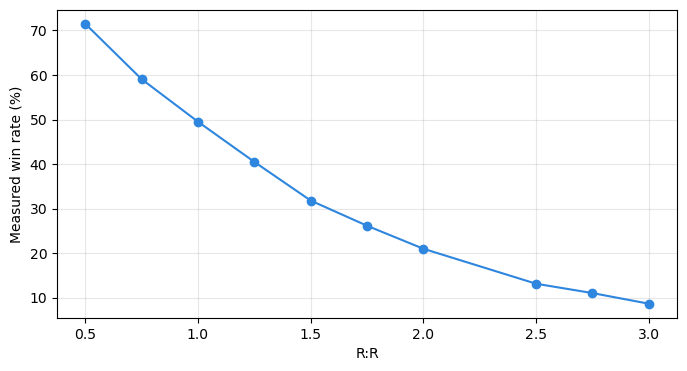

   0.5R  WR=71.5%   edge=+0.094R
  0.75R  WR=59.1%   edge=+0.091R
   1.0R  WR=49.5%   edge=+0.100R
  1.25R  WR=40.5%   edge=+0.096R
   1.5R  WR=31.8%   edge=+0.084R
  1.75R  WR=26.1%   edge=+0.087R
   2.0R  WR=21.0%   edge=+0.089R
   2.5R  WR=13.1%   edge=+0.088R
  2.75R  WR=11.0%   edge=+0.100R
   3.0R  WR= 8.6%   edge=+0.105R


In [10]:
E, cfg = build(STRATEGY, FIRM, OVERRIDES)
fig, wr_by_rr, edge_by_rr = measured_wr_curve(E, RR_GRID); plt.show()
for rr in RR_GRID:
    print(f"  {rr:>4}R  WR={wr_by_rr[rr]:5.1%}   edge={edge_by_rr[rr]:+.3f}R")

In [15]:
from edge_diagnostic import bracket_edge, sweep_configs
from strategies.kernel_pullback import get_strategy as kp

# make sure bars is your REAL 2-min data, loaded correctly:
bars = load_ohlc(DATA_PATH, rth_only=True, timeframe="2min", tz="America/New_York")
print(f"bars: {len(bars)}  ({bars.index[0]} -> {bars.index[-1]})")

bars: 248696  (2021-06-28 09:30:00-04:00 -> 2026-06-26 16:00:00-04:00)


In [17]:
# Step 1: is there extractable structure, and is the pipeline fair on THIS data?
bracket_edge(strat, bars, k_stop_atr=5, max_hold=MAX_HOLD, rr=2.0)

  strategy (kernel_pullback) edge=+0.033  WR=10.7%  n=3796  95%CI=[+0.004, +0.063]
  lookahead cheat (upper)    edge=+0.527   <- extractable edge ceiling
  random entry (zero base)   edge=+0.026
  -> marginal


{'edge': np.float64(0.03264048332937072),
 'ci': (np.float64(0.004418373148578829), np.float64(0.06259871597437097)),
 'cheat': np.float64(0.5265210501519786),
 'random': np.float64(0.025799372474373018),
 'n': 3796}

In [18]:
# Step 2: which trigger + stop width, on real data?
start_long = kp(trigger=TRIGGER, h=H, r=R, x_0=X0, lag=LAG,
                slope_len=SLOPE_LEN, slope_min=SLOPE_MIN,
                er_len=ER_LEN, er_min=ER_MIN, max_dist_atr=MAX_DIST_ATR, allow_long =True, allow_short=False)
bracket_edge(start_long, bars, k_stop_atr=5, max_hold=MAX_HOLD, rr=2.0)

  strategy (kernel_pullback) edge=+0.066  WR=10.0%  n=3387  95%CI=[+0.031, +0.100]
  lookahead cheat (upper)    edge=+0.527   <- extractable edge ceiling
  random entry (zero base)   edge=+0.053
  -> marginal


{'edge': np.float64(0.06558533059840838),
 'ci': (np.float64(0.030628336337314453), np.float64(0.10041013536164525)),
 'cheat': np.float64(0.5265210501519786),
 'random': np.float64(0.05326489784658572),
 'n': 3387}

In [19]:
strat_short = kp(trigger=TRIGGER, h=H, r=R, x_0=X0, lag=LAG,
                 slope_len=SLOPE_LEN, slope_min=SLOPE_MIN,
                 er_len=ER_LEN, er_min=ER_MIN, max_dist_atr=MAX_DIST_ATR,
                 allow_long=False, allow_short=True)
bracket_edge(strat_short, bars, k_stop_atr=K_STOP_ATR, max_hold=MAX_HOLD, rr=2.0)

  strategy (kernel_pullback) edge=+0.005  WR=11.9%  n=3340  95%CI=[-0.029, +0.036]
  lookahead cheat (upper)    edge=+0.527   <- extractable edge ceiling
  random entry (zero base)   edge=+0.041
  -> NOT distinguishable from random/zero


{'edge': np.float64(0.005268181974315344),
 'ci': (np.float64(-0.028683602834050366), np.float64(0.035696825444191616)),
 'cheat': np.float64(0.5265210501519786),
 'random': np.float64(0.04099650793505056),
 'n': 3340}

## 2) Optimal risk geometry for the chosen firm

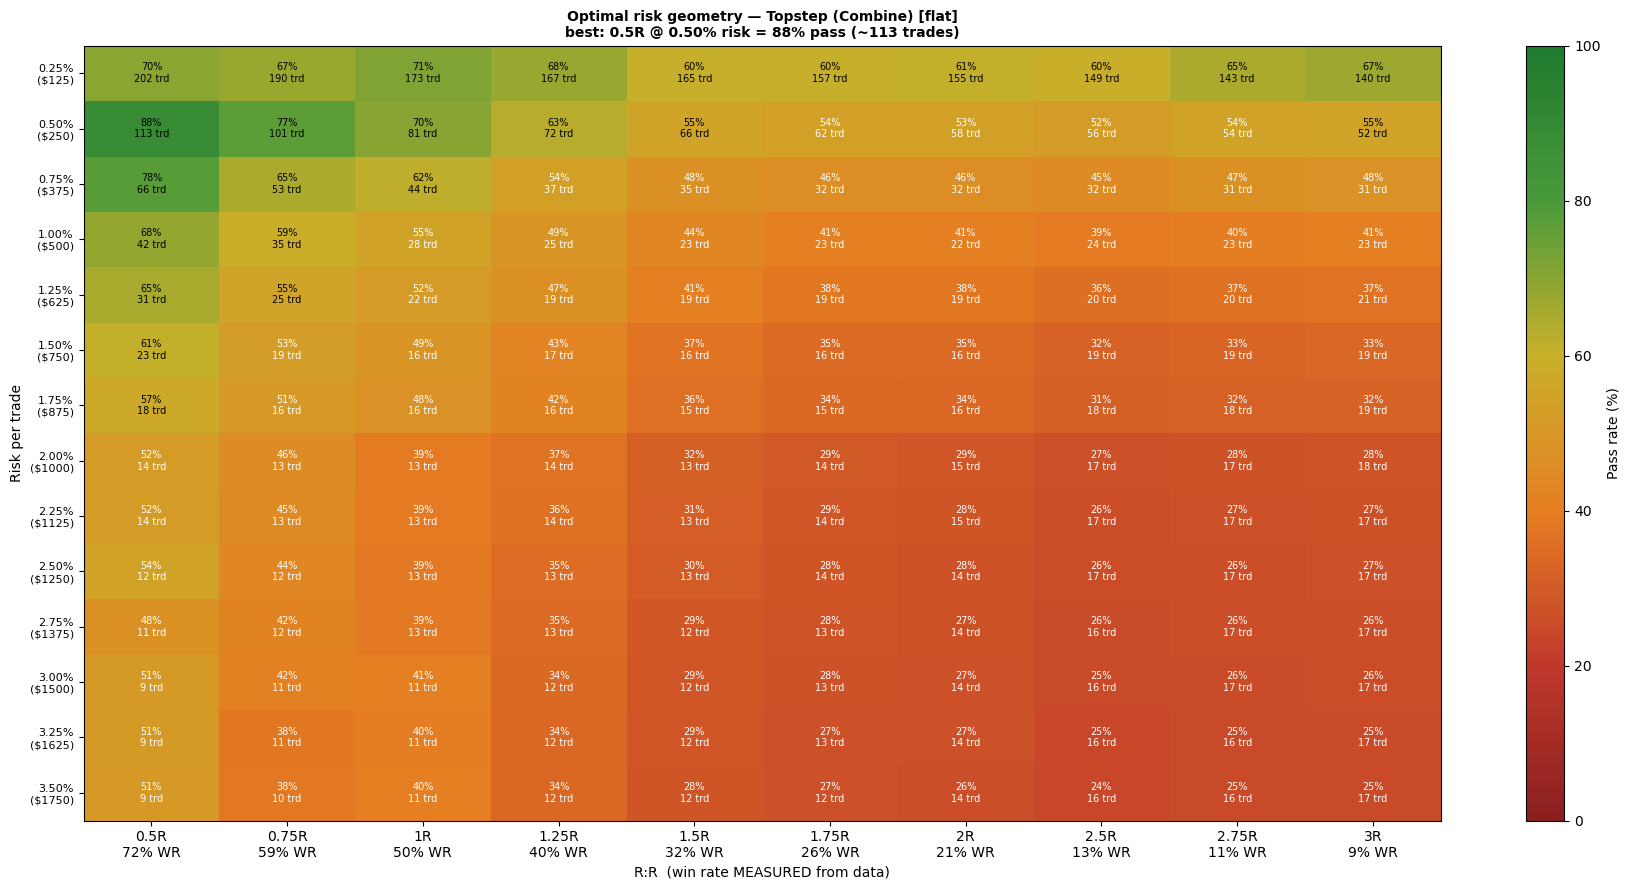

BEST for Topstep (Combine): 0.5R @ 0.50% risk -> 88% pass in ~113 trades (WR 72%)


In [11]:
fig, g = risk_rr_heatmap(FIRM, E, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                         n_paths=2000, max_trades=300); plt.show()
print(f"BEST for {FIRM.name}: {g['opt_rr']:g}R @ {g['opt_risk_pct']:.2f}% risk "
      f"-> {g['opt_pass_pct']:.0f}% pass in ~{g['opt_speed']:.0f} trades (WR {g['opt_wr']:.0%})")

In [7]:
from Backtest import load_ohlc
bars = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
print("rows:", len(bars))
print("range:", bars.index.min(), "->", bars.index.max())
print("has 2025:", (bars.index.year == 2025).any())
print("has 2026:", (bars.index.year == 2026).any())

rows: 1767373
range: 2021-06-27 20:00:00-04:00 -> 2026-06-26 16:59:00-04:00
has 2025: True
has 2026: True


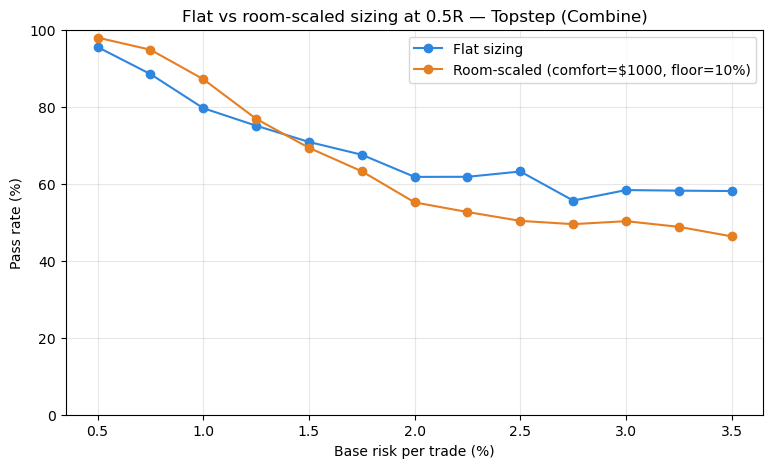

BEST room-scaled: 0.50% base risk -> 98% pass (flat at same risk: 96%)


In [8]:
# === ROOM-SCALED SIZING vs FLAT (size down in drawdown, steady when safe) ===
R_rs, days_rs = ledger_for_rr(E, g["opt_rr"])          # ledger at the heatmap's best R:R
strat_rs = EmpiricalStrategy(R_rs, name=f"new_jj {g['opt_rr']:g}R", day_ids=days_rs)

rp_axis = RISK_PCTS[RISK_PCTS >= 0.5]
flat_p, scaled_p = [], []
for rp in rp_axis:
    rd = FIRM.start_balance * rp / 100
    flat_p.append(simulate(strat_rs, FIRM, rd, n_paths=4000, max_trades=300,
                           sizing="flat").pass_rate * 100)
    scaled_p.append(simulate(strat_rs, FIRM, rd, n_paths=4000, max_trades=300,
                             sizing="room_scaled", comfort_room=COMFORT_ROOM,
                             min_risk_frac=MIN_RISK_FRAC).pass_rate * 100)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rp_axis, flat_p,   "-o", color="#2e86de", label="Flat sizing")
ax.plot(rp_axis, scaled_p, "-o", color="#e67e22",
        label=f"Room-scaled (comfort=${COMFORT_ROOM}, floor={MIN_RISK_FRAC:.0%})")
ax.set_xlabel("Base risk per trade (%)"); ax.set_ylabel("Pass rate (%)"); ax.set_ylim(0, 100)
ax.set_title(f"Flat vs room-scaled sizing at {g['opt_rr']:g}R — {FIRM.name}")
ax.legend(); ax.grid(alpha=.3); plt.show()

bi = int(np.argmax(scaled_p))
print(f"BEST room-scaled: {rp_axis[bi]:.2f}% base risk -> {scaled_p[bi]:.0f}% pass "
      f"(flat at same risk: {flat_p[bi]:.0f}%)")

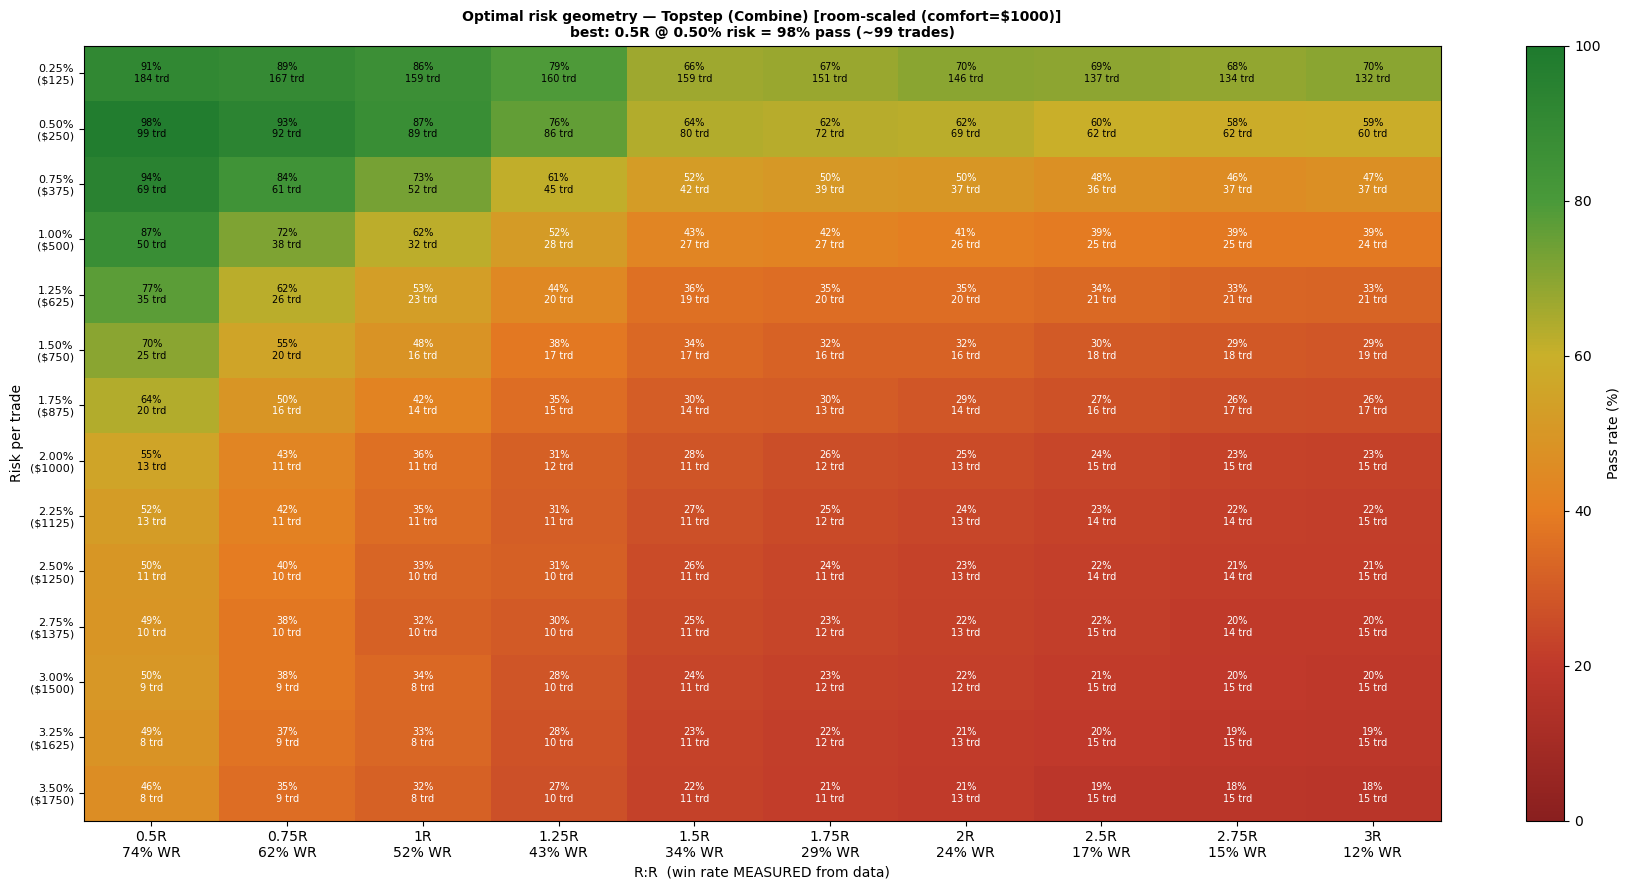

ROOM-SCALED best: 0.5R @ 0.50% risk -> 98% pass in ~99 trades


In [9]:
# === SAME HEATMAP, ROOM-SCALED SIZING ===
fig, g_rs = risk_rr_heatmap(FIRM, E, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                            n_paths=2000, max_trades=300,
                            sizing="room_scaled",
                            comfort_room=COMFORT_ROOM, min_risk_frac=MIN_RISK_FRAC)
plt.show()
print(f"ROOM-SCALED best: {g_rs['opt_rr']:g}R @ {g_rs['opt_risk_pct']:.2f}% risk "
      f"-> {g_rs['opt_pass_pct']:.0f}% pass in ~{g_rs['opt_speed']:.0f} trades")

### 2) Optimal Risk Geometry for Designated Months (i.e 2025 June - November)

2026-01-01 to 2026-06-30: 47,938 bars, 125 days
211 entries over 124 days (~1.70 trades/day) | new_jj on ?


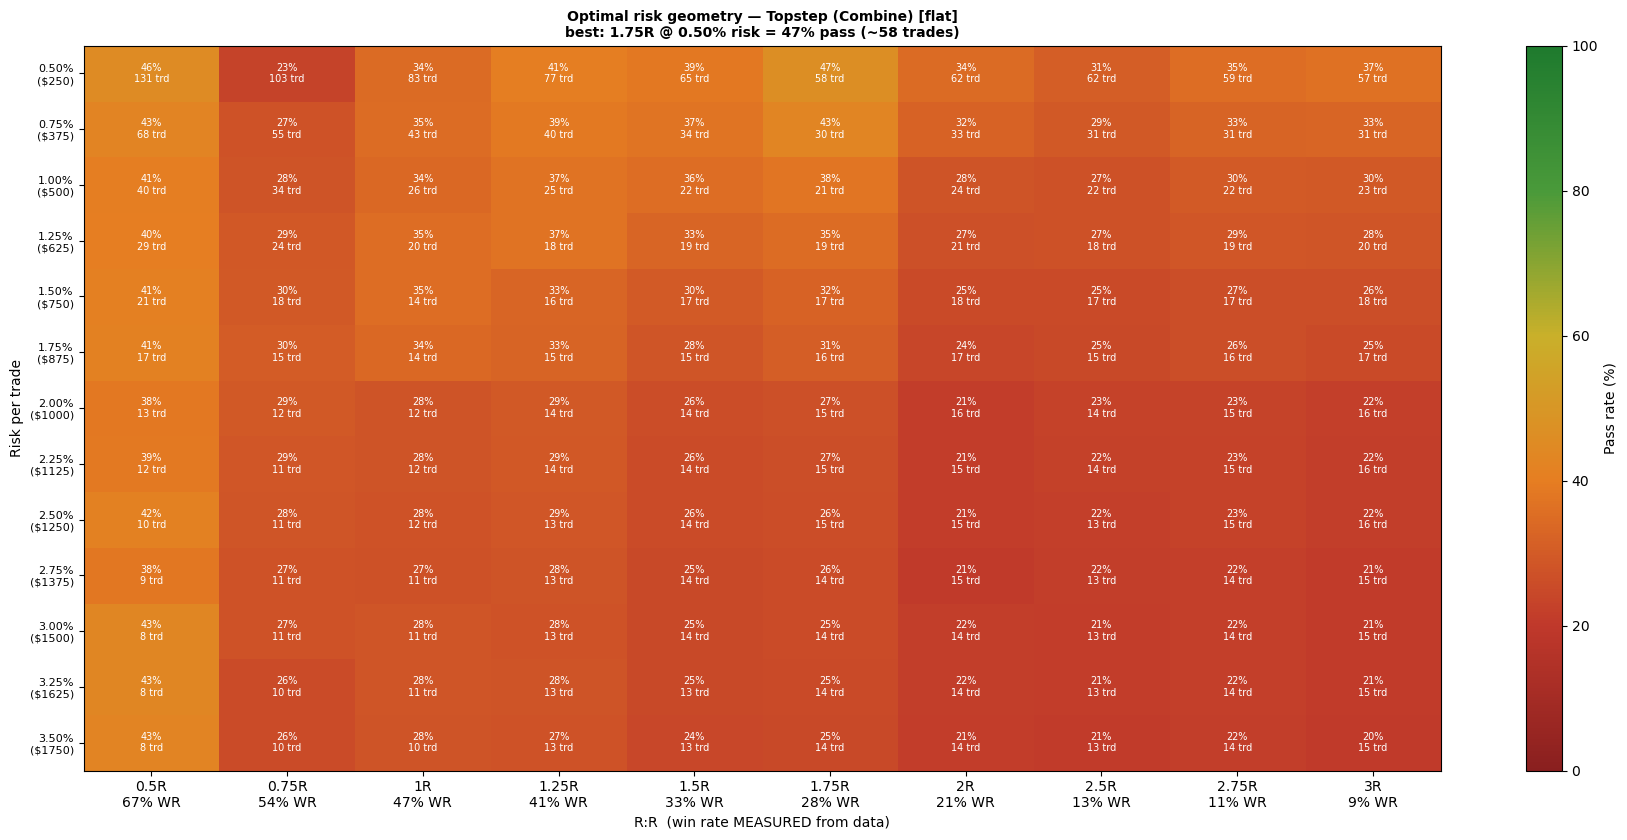

BEST (2026-01): 1.75R @ 0.50% -> 47% pass in ~58 trades (WR 28%)


In [10]:
PERIOD_START = "2026-01-01"
PERIOD_END = "2026-06-30"

bars_p = load_ohlc(DATA_PATH, rth_only=True, timeframe=None, tz="America/New_York")
bars_p = bars_p.loc[PERIOD_START:PERIOD_END]
print (f"{PERIOD_START} to {PERIOD_END}: {len(bars_p):,} bars, "
         f"{bars_p.index.normalize().nunique()} days")

E = backtest_entries(NewJJ(bos_tf=BOS_TF, swing_k=SWING_K), bars_p,
                     k_stop_atr=K_STOP_ATR, max_hold=MAX_HOLD)
print(E.summary())

RISK_PCTS_NO025 = RISK_PCTS[RISK_PCTS >= 0.5]   # ignore the 0.25% option

fig, g_p = risk_rr_heatmap(FIRM, E, risk_pcts=RISK_PCTS_NO025, rr_grid=RR_GRID,
                           n_paths=2000, max_trades=300); plt.show()
print(f"BEST ({PERIOD_START[:7]}): {g_p['opt_rr']:g}R @ {g_p['opt_risk_pct']:.2f}% "
      f"-> {g_p['opt_pass_pct']:.0f}% pass in ~{g_p['opt_speed']:.0f} trades "
      f"(WR {g_p['opt_wr']:.0%})")

### Risk Geometry Floor Optimization (!!!)
As shown above, different market periods produce different optimal risk-to-reward (R) settings because each month represents a distinct market regime. Averaging the results across all months provides a view of what worked on average, but this is of limited practical value. In live trading, we operate within a single market regime at a time—not the average of many.

To address this, the backtest is divided into an in-sample and an out-of-sample (OOS) period. Within the in-sample period, the data is further segmented into rolling two-month windows. A Risk × R parameter grid is evaluated on each window, and the resulting performance is assessed using robustness metrics, including the mean pass rate, minimum pass rate, and standard deviation.

The key idea behind this approach is to optimize for the **floor** rather than the **average**. For example, a parameter combination that achieves an average pass rate of 65% but falls to 20% during unfavorable months is less desirable than one that averages 58% but never drops below 45%. The latter is consistently tradable across different market regimes, whereas the former depends heavily on encountering favorable conditions. 

This concept on rboustness aims to identify paramter regions that remain **relatively** resilient acorss changing regimes, thereby reducing the likelihood of severe performance degradation in future. Ultimately, the simulator is not intended to have predictive value, its sole purpose is to identify risk geometery / configurations that have demonstrated the greatest stability across a range of historical conditions.

IS windows: 55 | OOS windows: 6


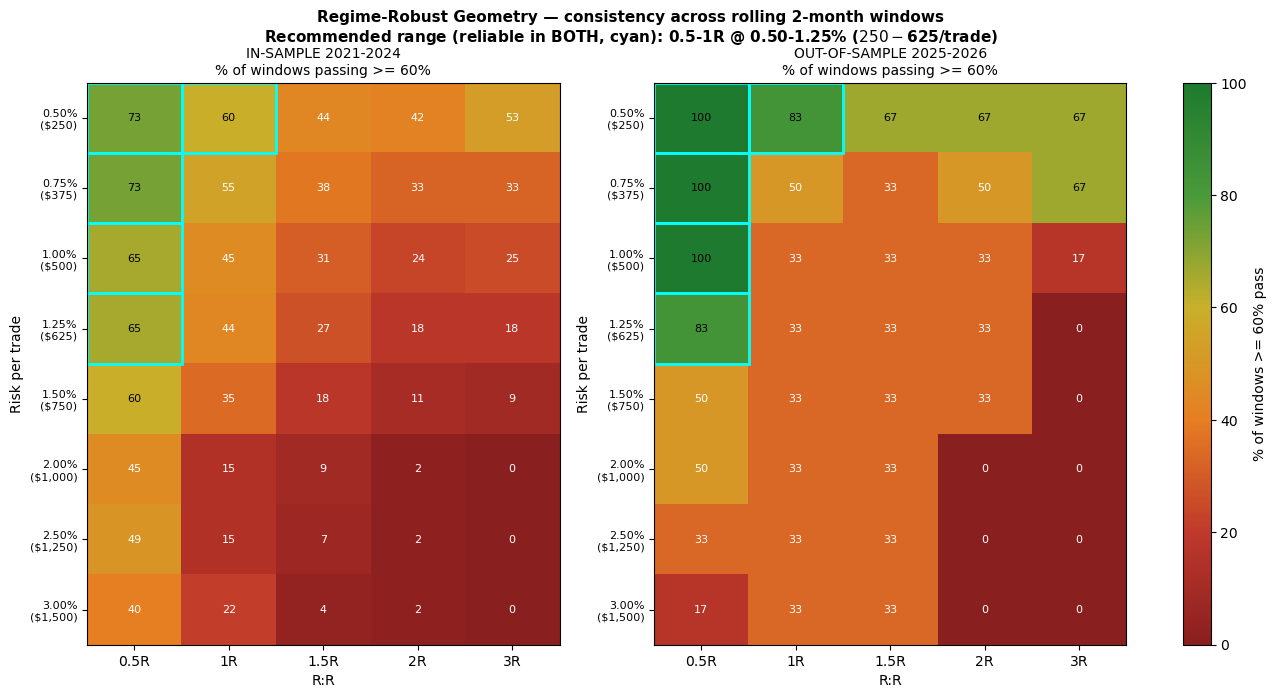


>>> RECOMMENDED RANGE: 0.5-1R @ 0.50-1.25% ($250-$625/trade), reliable in >=60% of windows in BOTH periods



,RR,risk_%,risk_$,IS_mean,IS_floor_p25,IS_worst,IS_%win>=60,OOS_mean,OOS_%win>=60,robust_score
0,0.50,0.50,$250,74,51,1,73,87,100,73
1,0.50,0.75,$375,72,54,3,73,80,100,73
2,0.50,1.25,$625,65,48,9,65,68,83,65
3,0.50,1.00,$500,67,51,7,65,72,100,65
4,1.00,0.50,$250,61,23,0,60,70,83,60
5,3.00,0.50,$250,50,16,0,53,68,67,53
6,1.00,0.75,$375,57,25,2,55,65,50,50
7,0.50,1.50,$750,63,46,11,60,65,50,50
8,0.50,2.00,"$1,000",55,42,11,45,59,50,45
9,1.50,0.50,$250,50,16,1,44,68,67,44


In [11]:
# === REGIME-ROBUST GEOMETRY: rolling 2-month windows, IS vs OOS ===
import numpy as np, pandas as pd
from Robustness import window_pass_grids, plot_summary, summary_table
from strategies.new_jj import NewJJ

bars_all = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
IS  = bars_all.loc["2021-01-01":"2025-12-31"]     # in-sample
OOS = bars_all.loc["2026-01-01":"2026-12-31"]     # out-of-sample (never tuned on)

factory = lambda: NewJJ(bos_tf=BOS_TF, swing_k=SWING_K)
RISK_R  = np.array([0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0])
RR_R    = [0.5, 1.0, 1.5, 2.0, 3.0]
THRESH  = 60     # "a good window" = pass rate >= this

is_grids,  _, isc = window_pass_grids(factory, IS,  FIRM, RISK_R, RR_R, k_stop_atr=K_STOP_ATR,
                                      months=2, step_months=1, n_paths=700, min_trades=25)
oos_grids, _, oc  = window_pass_grids(factory, OOS, FIRM, RISK_R, RR_R, k_stop_atr=K_STOP_ATR,
                                      months=2, step_months=1, n_paths=700, min_trades=25)
print(f"IS windows: {len(is_grids)} | OOS windows: {len(oos_grids)}")

fig, rec = plot_summary(is_grids, oos_grids, RISK_R, RR_R,
                        start_balance=FIRM.start_balance, threshold=THRESH); plt.show()

print(f"\n>>> RECOMMENDED RANGE: {rec['rr_lo']:g}-{rec['rr_hi']:g}R @ "
      f"{rec['risk_lo']:.2f}-{rec['risk_hi']:.2f}% "
      f"(${rec['dollar_lo']:,.0f}-${rec['dollar_hi']:,.0f}/trade), "
      f"reliable in >={rec['bar']:.0f}% of windows in BOTH periods\n")

tbl = summary_table(is_grids, oos_grids, RISK_R, RR_R, start_balance=FIRM.start_balance, threshold=THRESH)
fmt = {"RR":"{:.2f}","risk_%":"{:.2f}","risk_$":"${:,.0f}","IS_mean":"{:.0f}","IS_floor_p25":"{:.0f}",
       "IS_worst":"{:.0f}",f"IS_%win>={THRESH}":"{:.0f}","OOS_mean":"{:.0f}",
       f"OOS_%win>={THRESH}":"{:.0f}","robust_score":"{:.0f}"}
display(tbl.head(10).style.format(fmt).set_caption("Most robust geometries (reliable in both periods)"))

## 3) Risk curve + equity paths at the optimal R:R

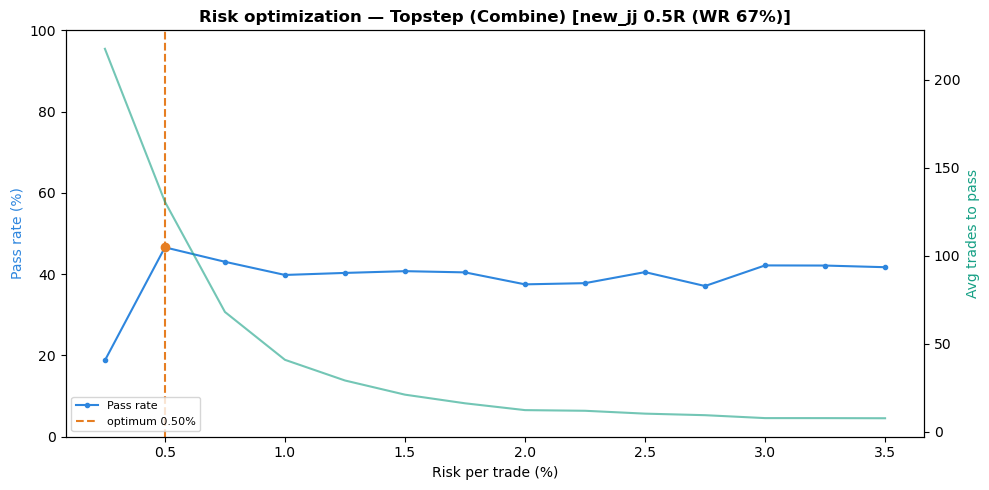

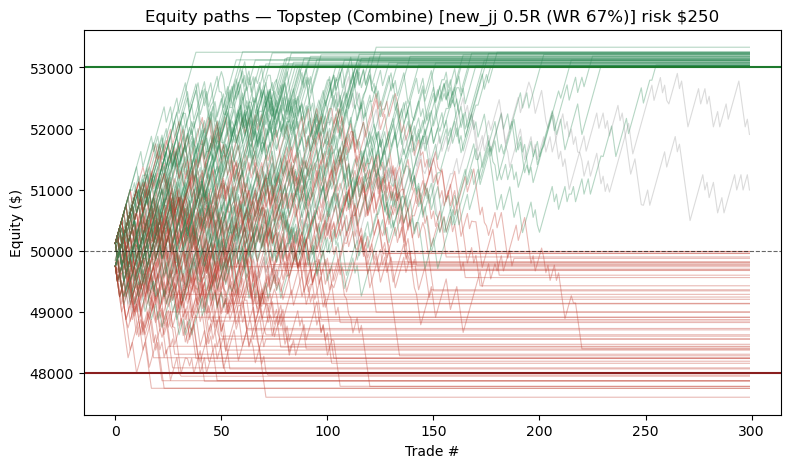

In [12]:
R, days = ledger_for_rr(E, g["opt_rr"])
strat = EmpiricalStrategy(R, name=f"new_jj {g['opt_rr']:g}R (WR {measured_winrate(E, g['opt_rr']):.0%})",
                          day_ids=days)
fig, r = plot_risk_curve(strat, FIRM, risk_pcts=RISK_PCTS, n_paths=3000, max_trades=300); plt.show()
fig = plot_equity_paths(FIRM, strat, risk_per_trade=r["opt_risk_dollars"],
                        n_show=120, max_trades=300); plt.show()

## 4) Cross-firm optimal risk

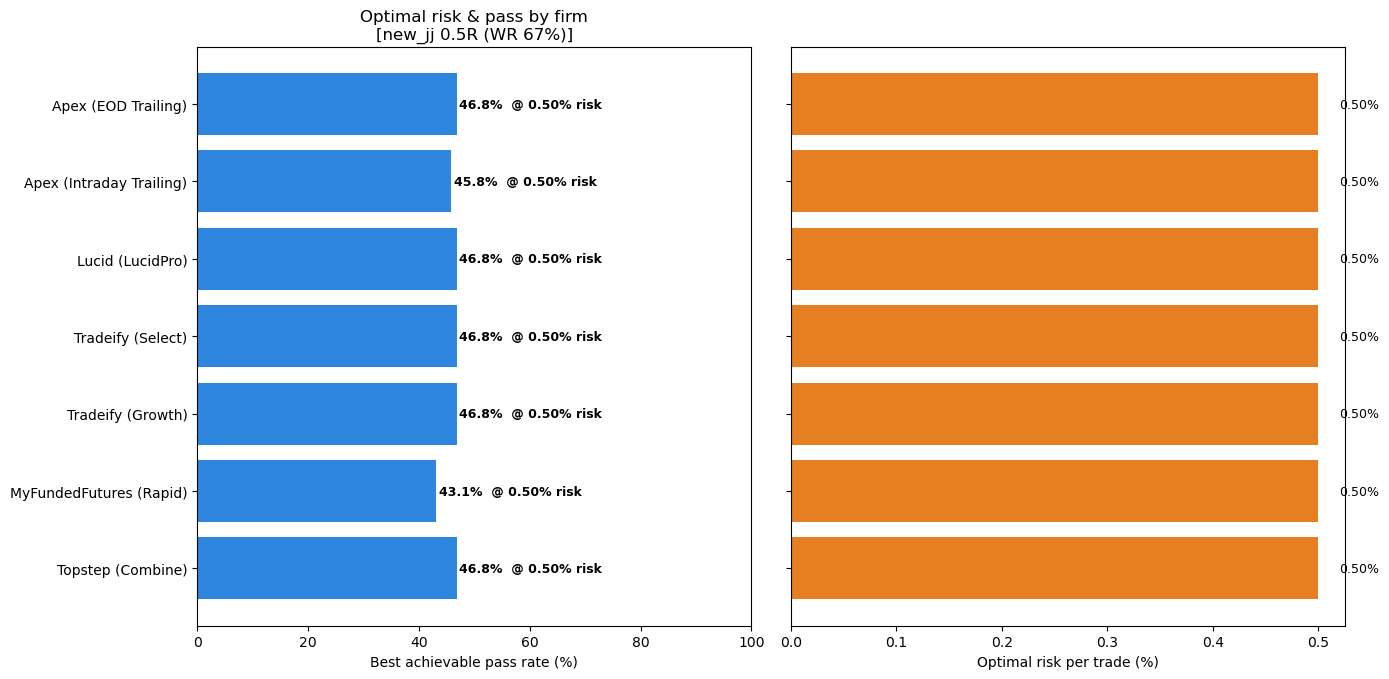

In [13]:
results, fig = optimal_risk_by_firm(strat, get_firm, ALL_FIRMS,
    risk_pcts=RISK_PCTS, n_paths=2500, max_trades=300); plt.show()

## 5) Time to pass by firm

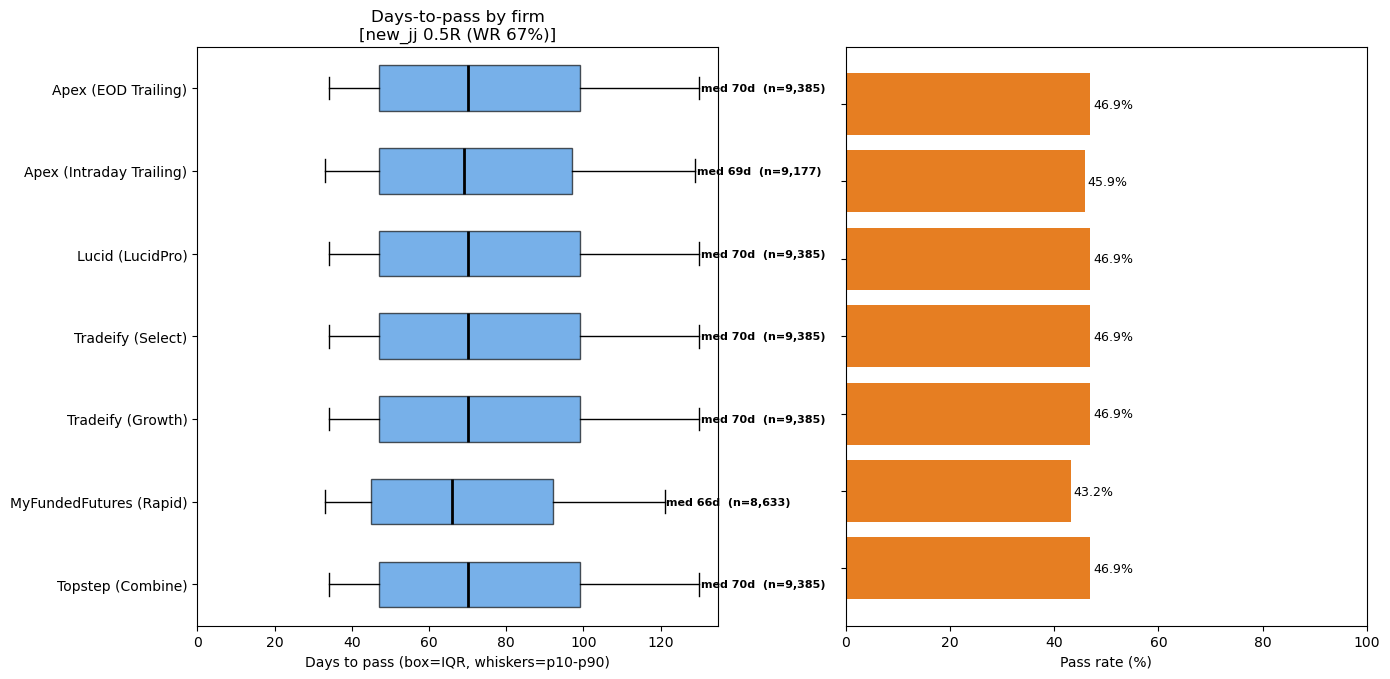

AttributeError: 'dict' object has no attribute 'to_string'

In [14]:
results, fig, summary = days_to_pass_by_firm(strat, get_firm, ALL_FIRMS,
    risk_pcts=RISK_PCTS, n_paths=2500, max_trades=300, dist_paths=20000); plt.show()
print(summary.to_string(index=False))

## Add-on — sweep stop width (K_STOP_ATR)
Independent of the cells above. Uses `K_STOP_ATR_GRID` from the KNOBS to find the
stop width with the best pass rate for this firm.

In [ ]:
rows = []
for kstop in K_STOP_ATR_GRID:
    Ek = backtest_entries(NewJJ(bos_tf=BOS_TF, swing_k=SWING_K), bars,
                          k_stop_atr=kstop, max_hold=MAX_HOLD)
    if len(Ek.day_ids) < 100:
        print(f"K={kstop}: only {len(Ek.day_ids)} trades — skipping"); continue
    wr1 = (ledger_for_rr(Ek, 1.0)[0] > 0).mean()
    gk = optimal_geometry(FIRM, Ek, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                          n_paths=1500, max_trades=300)
    rows.append((kstop, len(Ek.day_ids), wr1*100, gk['opt_rr'], gk['opt_risk_pct'],
                 gk['opt_pass_pct'], gk['opt_speed']))
print(f"\n{'K':>4}{'trades':>8}{'WR@1R':>7}{'RR':>6}{'risk%':>7}{'pass%':>7}{'toPass':>8}")
for row in sorted(rows, key=lambda x: -x[5]):
    print(f"{row[0]:>4}{row[1]:>8}{row[2]:>6.0f}%{row[3]:>6g}{row[4]:>7.2f}{row[5]:>6.0f}%{row[6]:>8.0f}")
if rows:
    plt.figure(figsize=(8,4)); plt.plot([x[0] for x in rows], [x[5] for x in rows], "-o")
    plt.xlabel("K_STOP_ATR"); plt.ylabel("Best pass rate (%)")
    plt.title(f"Pass rate vs stop width — {FIRM.name}"); plt.grid(alpha=.3); plt.show()